# DATA SCIENCE 500 ASSIGNMENT

## Book Market Analytics – Books to Scrape

**Institution:** Richfield Graduate Institute of Technology

**Student Name:** Junior Jimmy Nkgapele

**Student Number:** 402418667

**Module:** Data Science 500

### Project Overview

This project investigates book pricing patterns using data collected from the Books to Scrape website.

A total of 1,000 books were collected using Python, Requests and BeautifulSoup. The dataset was cleaned, explored through statistical visualisations and used to train a Linear Regression model for predicting book prices.

The project follows five main stages:

1. Data Acquisition
2. Data Cleaning and Preparation
3. Exploratory Data Analysis and Visualisation
4. Predictive Modelling
5. Model Evaluation and Interpretation

The objective is to understand catalogue pricing patterns and assess whether publicly available book characteristics can be used to predict book prices.

In [6]:

# Import required Python libraries

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("All libraries imported successfully!")


All libraries imported successfully!


## 1. Data Acquisition — Web Scraping

### 1.1 Data Source

The dataset was collected from the Books to Scrape website (https://books.toscrape.com), a website designed for practising web scraping.

Python's Requests library was used to retrieve website pages, while BeautifulSoup was used to extract structured information from the HTML.

The scraping process collected 1,000 books from 50 catalogue pages.

The extracted attributes included:

- Book title
- Price in British pounds (GBP)
- Star rating
- Stock availability
- Stock quantity
- Book genre
- Product URL

The collected records were saved in a CSV file named `books_raw.csv` for further processing.

In [15]:

# COMPLETE WEB SCRAPING PROCESS
# Data Science 500 - Books to Scrape

import requests
import pandas as pd
import re
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/"

books_data = []

session = requests.Session()

# Visit all 50 catalogue pages
for page in range(1, 51):

    if page == 1:
        url = BASE_URL
    else:
        url = urljoin(
            BASE_URL,
            f"catalogue/page-{page}.html"
        )

    print(f"Scraping page {page}...")

    response = session.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    books = soup.find_all(
        "article",
        class_="product_pod"
    )

    for book in books:

        # Extract title
        title = book.h3.a["title"]

        # Extract price
        price_text = book.find(
            "p",
            class_="price_color"
        ).get_text(strip=True)

        price = float(
            re.search(
                r"\d+\.\d+",
                price_text
            ).group()
        )

        # Extract star rating
        rating = book.find(
            "p",
            class_="star-rating"
        )["class"][1]

        # Extract availability
        availability = book.find(
            "p",
            class_="instock availability"
        ).get_text(" ", strip=True)

        # Get individual book page
        product_url = urljoin(
            url,
            book.h3.a["href"]
        )

        product_response = session.get(
            product_url,
            timeout=20
        )

        product_response.raise_for_status()

        product_soup = BeautifulSoup(
            product_response.text,
            "html.parser"
        )

        # Extract genre
        breadcrumbs = product_soup.select(
            "ul.breadcrumb li a"
        )

        genre = (
            breadcrumbs[2].get_text(strip=True)
            if len(breadcrumbs) > 2
            else "Unknown"
        )

        # Extract stock quantity
        stock_element = product_soup.select_one(
            "p.instock.availability"
        )

        stock_text = (
            stock_element.get_text(" ", strip=True)
            if stock_element
            else availability
        )

        stock_match = re.search(
            r"\((\d+) available\)",
            stock_text
        )

        stock_quantity = (
            int(stock_match.group(1))
            if stock_match
            else None
        )

        # Store book information
        books_data.append({
            "Title": title,
            "Price_GBP": price,
            "Rating": rating,
            "Availability": availability,
            "Stock_Quantity": stock_quantity,
            "Genre": genre,
            "Product_URL": product_url
        })

    time.sleep(0.3)

# Convert scraped data to DataFrame
df_scraped = pd.DataFrame(books_data)

# Save raw dataset
df_scraped.to_csv(
    "books_raw.csv",
    index=False,
    encoding="utf-8"
)

print("\nWEB SCRAPING COMPLETED")
print("Total books:", len(df_scraped))

display(df_scraped.head())


Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...

WEB SCRA

,Title,Price_GBP,Rating,Availability,Stock_Quantity,Genre,Product_URL
0,A Light in the Attic,51.77,Three,In stock,22,Poetry,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,In stock,20,Historical Fiction,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,In stock,20,Fiction,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,In stock,20,Mystery,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,20,History,https://books.toscrape.com/catalogue/sapiens-a...


### 1.2 Web Scraping Implementation

The data acquisition process was implemented using Python's Requests and BeautifulSoup libraries.

The scraper visited 50 catalogue pages on the Books to Scrape website. For each book, it extracted the title, price, star rating and stock availability from the catalogue listing.

Individual product pages were accessed to retrieve additional information, including book genre and available stock quantity.

The collected information was stored in a Pandas DataFrame and exported to `books_raw.csv`.

The scraper included HTTP status checks, request timeouts and a short delay between catalogue pages.

This approach produced a dataset containing 1,000 book records, exceeding the assignment's minimum requirement of 200 books.

**Data Source:** Books to Scrape (n.d.) *Books to Scrape*. Available at: https://books.toscrape.com/ (Accessed: 14 October 2026).

In [16]:

# Load the previously scraped dataset

df_raw = pd.read_csv("books_raw.csv")

# Display the total number of books
print("Total books collected:", len(df_raw))

# Display the first five records
display(df_raw.head())

# Display the dataset structure
print("\nDataset Information:")
df_raw.info()

# Check the columns
print("\nDataset Columns:")
print(df_raw.columns.tolist())


Total books collected: 1000


,Title,Price_GBP,Rating,Availability,Stock_Quantity,Genre,Product_URL
0,A Light in the Attic,51.77,Three,In stock,22,Poetry,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,In stock,20,Historical Fiction,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,In stock,20,Fiction,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,In stock,20,Mystery,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,20,History,https://books.toscrape.com/catalogue/sapiens-a...



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Title           1000 non-null   str    
 1   Price_GBP       1000 non-null   float64
 2   Rating          1000 non-null   str    
 3   Availability    1000 non-null   str    
 4   Stock_Quantity  1000 non-null   int64  
 5   Genre           1000 non-null   str    
 6   Product_URL     1000 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 54.8 KB

Dataset Columns:
['Title', 'Price_GBP', 'Rating', 'Availability', 'Stock_Quantity', 'Genre', 'Product_URL']


### 2. Data Cleaning and Preparation

**2.1 Data Cleaning Methodology**

The raw dataset containing 1,000 books was processed to improve data quality and prepare the information for exploratory analysis and predictive modelling.

The following cleaning procedures were applied:

1. Missing Values: The dataset was examined to identify incomplete records.
2. Duplicate Removal: Duplicate book records were removed using their unique product URLs.
3. Text Standardisation: Unnecessary whitespace was removed from text fields.
4. Price Conversion: Book prices were converted into numeric values suitable for statistical analysis.
5. Rating Conversion: Star ratings were converted from words (One to Five) into numerical values (1 to 5).
6. Stock Quantity Conversion: Stock quantities were converted into numeric values, preserving missing quantities where the information was unavailable.
7. Genre Cleaning: Missing genre labels were replaced with "Unknown".
8. Data Validation: Records containing invalid prices or ratings were excluded.

These procedures produced a structured dataset suitable for visualisation and machine learning.

In [17]:

# DATA CLEANING AND PREPARATION

df_clean = df_raw.copy()

print("Original dataset shape:", df_clean.shape)

# Check missing values before cleaning
print("\nMissing values before cleaning:")
print(df_clean.isnull().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates(
    subset=["Product_URL"]
)

# Standardise text columns
text_columns = [
    "Title",
    "Rating",
    "Availability",
    "Genre"
]

for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

# Convert price into numeric format
df_clean["Price_GBP"] = pd.to_numeric(
    df_clean["Price_GBP"],
    errors="coerce"
)

# Convert ratings from words to numbers
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df_clean["Rating_Numeric"] = (
    df_clean["Rating"].map(rating_mapping)
)

# Convert stock quantities to numeric values
df_clean["Stock_Quantity"] = pd.to_numeric(
    df_clean["Stock_Quantity"],
    errors="coerce"
)

# Handle missing genre values
df_clean["Genre"] = (
    df_clean["Genre"].fillna("Unknown")
)

# Remove invalid price and rating records
df_clean = df_clean.dropna(
    subset=["Price_GBP", "Rating_Numeric"]
)

df_clean = df_clean[
    (df_clean["Price_GBP"] > 0) &
    (df_clean["Rating_Numeric"].between(1, 5))
].copy()

# Save cleaned dataset
df_clean.to_csv(
    "books_cleaned.csv",
    index=False
)

# Display cleaning results
print("\nCleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nFirst five cleaned records:")
display(df_clean.head())

print("\nData cleaning completed successfully!")


Original dataset shape: (1000, 7)

Missing values before cleaning:
Title             0
Price_GBP         0
Rating            0
Availability      0
Stock_Quantity    0
Genre             0
Product_URL       0
dtype: int64

Cleaned dataset shape: (1000, 8)

Missing values after cleaning:
Title             0
Price_GBP         0
Rating            0
Availability      0
Stock_Quantity    0
Genre             0
Product_URL       0
Rating_Numeric    0
dtype: int64

First five cleaned records:


,Title,Price_GBP,Rating,Availability,Stock_Quantity,Genre,Product_URL,Rating_Numeric
0,A Light in the Attic,51.77,Three,In stock,22,Poetry,https://books.toscrape.com/catalogue/a-light-i...,3
1,Tipping the Velvet,53.74,One,In stock,20,Historical Fiction,https://books.toscrape.com/catalogue/tipping-t...,1
2,Soumission,50.10,One,In stock,20,Fiction,https://books.toscrape.com/catalogue/soumissio...,1
3,Sharp Objects,47.82,Four,In stock,20,Mystery,https://books.toscrape.com/catalogue/sharp-obj...,4
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,20,History,https://books.toscrape.com/catalogue/sapiens-a...,5



Data cleaning completed successfully!


### 2.2 Data Cleaning Results

The original dataset contained 1,000 book records and seven attributes.

Following data cleaning and validation, 1,000 records were retained, with an additional numerical rating column created for analysis.

The final dataset contained eight attributes and was saved as `books_cleaned.csv`.

Missing stock quantities, where present, were retained as missing rather than being incorrectly treated as zero. This preserves the distinction between unknown stock levels and confirmed out-of-stock products.

The cleaned dataset was subsequently used for exploratory data analysis and Linear Regression modelling.

## 3. Exploratory Data Analysis and Visualisation

### 3.1 Introduction

Exploratory Data Analysis (EDA) was conducted to investigate book pricing patterns, customer rating distributions and differences in prices across book genres.

The analysis used Matplotlib and Seaborn to produce four visualisations:

1. Distribution of book prices.
2. Distribution of star ratings.
3. Average book prices across the ten most common genres.
4. Relationship between book prices and star ratings.

These visualisations help identify catalogue characteristics and assess potential relationships between the variables used for predictive modelling.

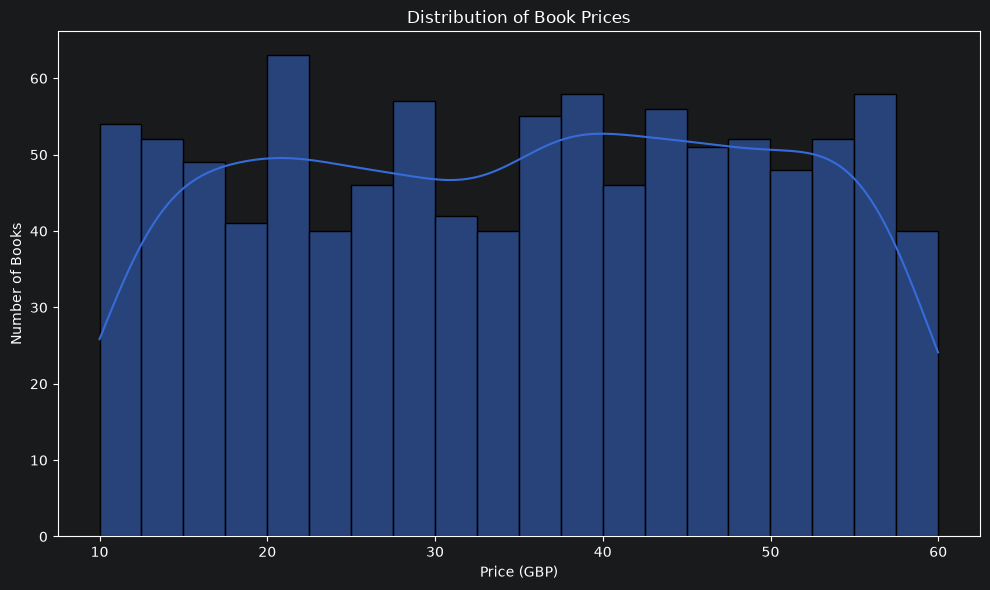

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price_GBP, dtype: float64


In [18]:

# GRAPH 1: Distribution of Book Prices

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Price_GBP",
    bins=20,
    kde=True
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("graphs/price_distribution.png", dpi=300)
plt.show()

# Display price statistics
print(df_clean["Price_GBP"].describe())


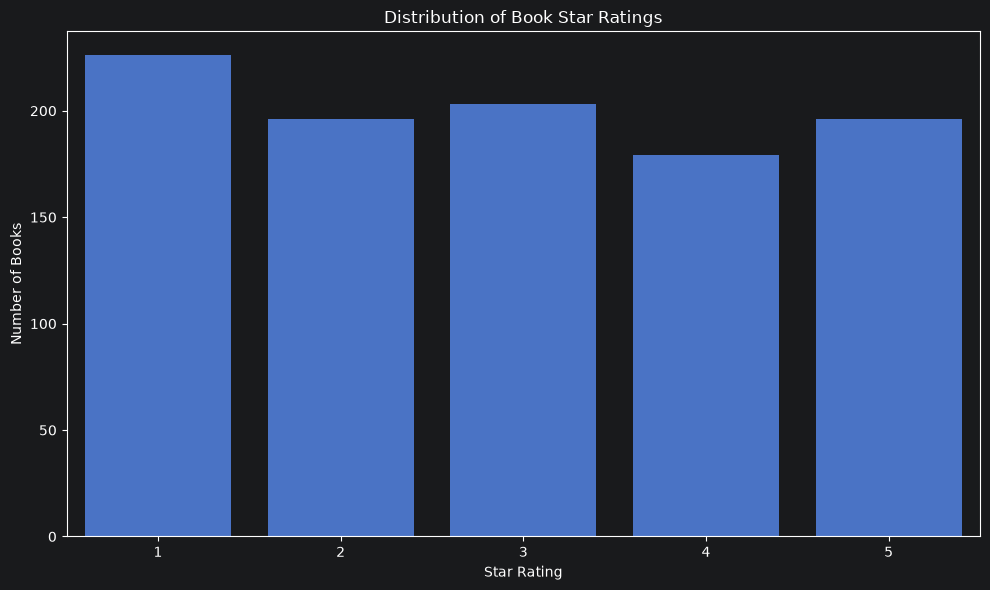

Rating_Numeric
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


In [19]:

# GRAPH 2: Distribution of Star Ratings

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x="Rating_Numeric",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Book Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.savefig("graphs/rating_distribution.png", dpi=300)
plt.show()

# Display rating frequencies
print(df_clean["Rating_Numeric"].value_counts().sort_index())


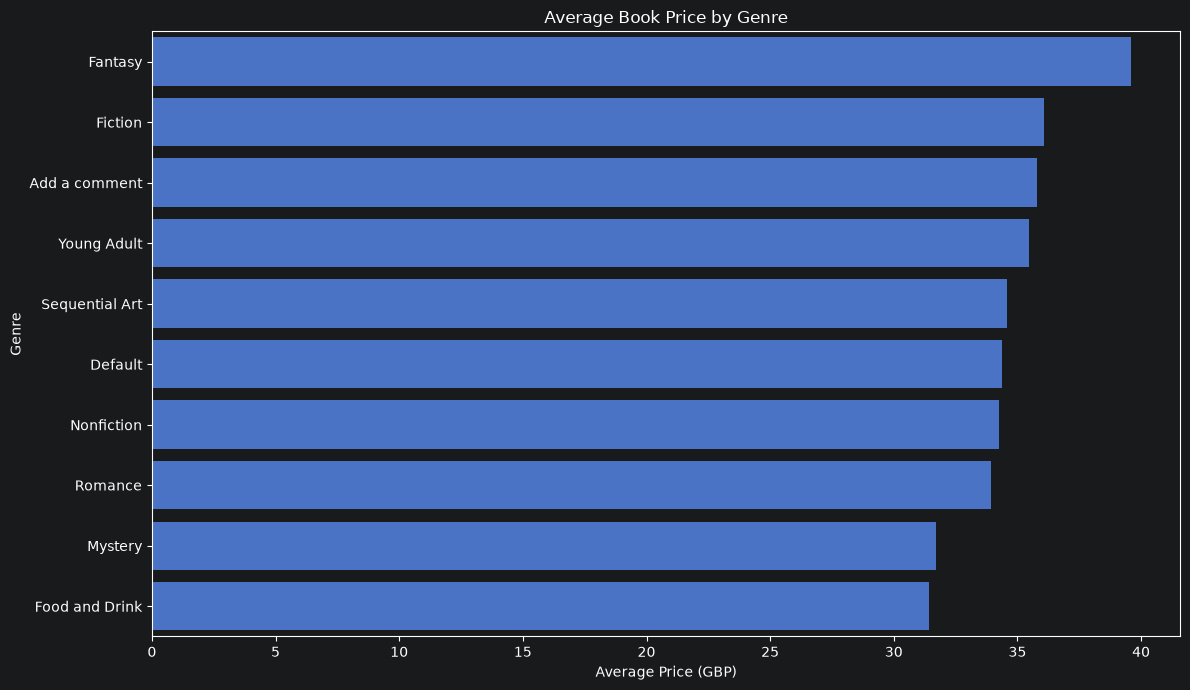

Genre
Fantasy           39.593958
Fiction           36.066615
Add a comment     35.796418
Young Adult       35.449074
Sequential Art    34.572267
Default           34.392697
Nonfiction        34.260182
Romance           33.933714
Mystery           31.719062
Food and Drink    31.414667
Name: Price_GBP, dtype: float64


In [20]:

# GRAPH 3: Average Price by Genre

top_genres = (
    df_clean["Genre"]
    .value_counts()
    .head(10)
    .index
)

genre_prices = (
    df_clean[df_clean["Genre"].isin(top_genres)]
    .groupby("Genre")["Price_GBP"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_prices.values,
    y=genre_prices.index
)

plt.title("Average Book Price by Genre")
plt.xlabel("Average Price (GBP)")
plt.ylabel("Genre")

plt.tight_layout()
plt.savefig("graphs/genre_prices.png", dpi=300)
plt.show()

print(genre_prices)


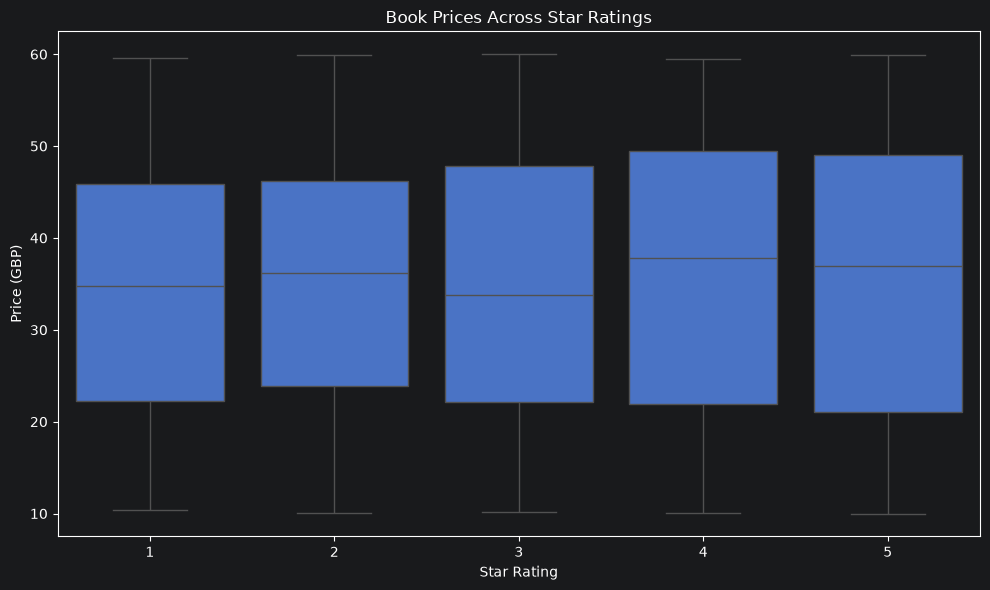

                count       mean  median
Rating_Numeric                          
1                 226  34.561195  34.770
2                 196  34.810918  36.215
3                 203  34.692020  33.780
4                 179  36.093296  37.800
5                 196  35.374490  36.900


In [21]:

# GRAPH 4: Book Prices Across Star Ratings

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="Rating_Numeric",
    y="Price_GBP",
    order=[1, 2, 3, 4, 5]
)

plt.title("Book Prices Across Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Price (GBP)")

plt.tight_layout()
plt.savefig("graphs/price_vs_rating.png", dpi=300)
plt.show()

print(
    df_clean.groupby("Rating_Numeric")["Price_GBP"]
    .agg(["count", "mean", "median"])
)


### 3.2 Interpretation of Visualisations

**Book Price Distribution**

The price distribution graph illustrates the frequency of different book prices within the catalogue. It provides an overview of the pricing range and helps identify whether prices are concentrated within particular intervals.

**Star Rating Distribution**

The star rating distribution shows the number of books assigned each rating from one to five stars. This helps identify the relative frequency of different rating categories.

**Average Price by Genre**

The genre comparison graph highlights differences in average book prices among the ten most common genres. These differences can be investigated to determine whether genre may be useful as a predictor of book prices.

**Book Prices Across Star Ratings**

The boxplot compares the distributions of book prices across the five rating levels. Overlapping price distributions would suggest that star ratings alone may have limited usefulness for predicting book prices.

### 3.3 Summary

The exploratory analysis provides a foundation for investigating book pricing patterns and selecting features for predictive modelling.

The findings should be interpreted with caution because Books to Scrape is a demonstration website rather than a commercial bookstore. Therefore, observed pricing patterns may not reflect real-world market behaviour.

## 4. Predictive Modelling — Linear Regression

### 4.1 Model Development

A Linear Regression model was developed to estimate book prices using information extracted from Books to Scrape.

The dependent variable (target) was `Price_GBP`.

The independent variables (features) were:

- `Rating_Numeric`: Numerical star rating from 1 to 5.
- `Genre`: Book category.
- `Stock_Quantity`: Number of copies available.
- `Title_Length`: Number of characters in the book title.

Categorical genre values were transformed using One-Hot Encoding. Missing numerical values were handled using median imputation.

The dataset was divided into 80% training data and 20% testing data using a fixed random state of 42 for reproducibility.

The model was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and the R-squared (R²) score.

In [22]:

# LINEAR REGRESSION MODEL

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create modelling dataset
model_df = df_clean.copy()

# Feature engineering
model_df["Title_Length"] = (
    model_df["Title"].fillna("").str.len()
)

# Select independent and dependent variables
features = [
    "Rating_Numeric",
    "Genre",
    "Stock_Quantity",
    "Title_Length"
]

X = model_df[features]
y = model_df["Price_GBP"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Define feature types
numeric_features = [
    "Rating_Numeric",
    "Stock_Quantity",
    "Title_Length"
]

categorical_features = ["Genre"]

# Prepare numeric features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train model
model.fit(X_train, y_train)

# Predict book prices
y_pred = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"MAE: £{mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: £{rmse:.2f}")
print(f"R-squared: {r2:.4f}")


LINEAR REGRESSION RESULTS
-------------------------
Training records: 800
Testing records: 200
MAE: £12.91
MSE: 225.26
RMSE: £15.01
R-squared: -0.0724


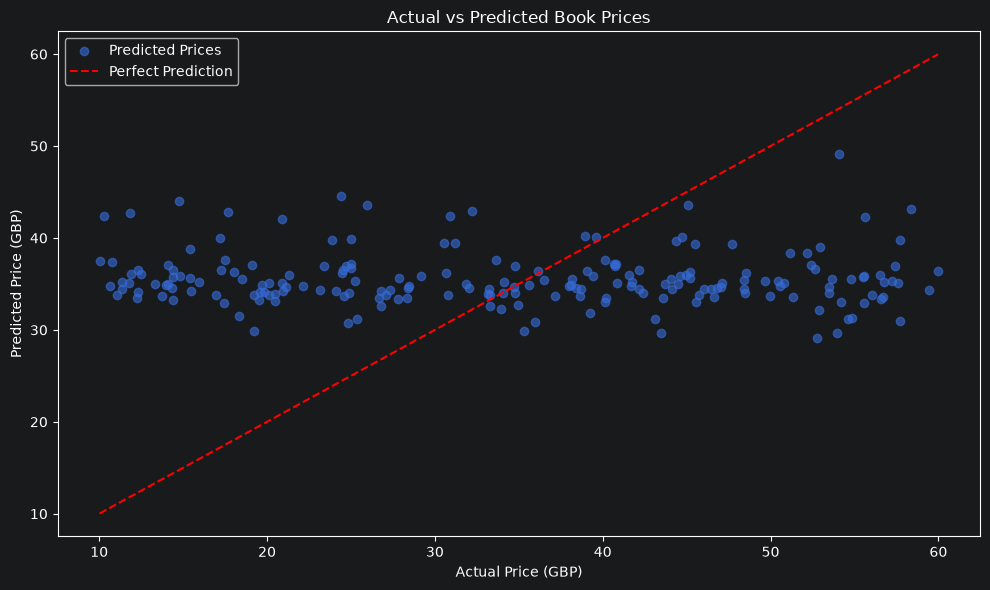

Predictions saved successfully!


In [23]:

# GRAPH 5: Actual vs Predicted Prices

from pathlib import Path

Path("graphs").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    label="Predicted Prices"
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (GBP)")
plt.ylabel("Predicted Price (GBP)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "graphs/actual_vs_predicted.png",
    dpi=300
)

plt.show()

# Save predictions
predictions_df = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": y_pred
})

predictions_df.to_csv(
    "model_predictions.csv",
    index=False
)

print("Predictions saved successfully!")


### 4.2 Model Evaluation and Interpretation

The Linear Regression model was evaluated using 200 testing records.

The previously recorded model results were:

- **MAE:** £12.91
- **MSE:** 225.26
- **RMSE:** £15.01
- **R²:** -0.0724

The Mean Absolute Error indicates that predicted prices differed from actual book prices by approximately £12.91 on average.

The Root Mean Squared Error of £15.01 indicates the magnitude of prediction errors, with larger errors receiving greater weight.

The negative R² score indicates that the model performed worse than a simple mean-price prediction baseline on the testing dataset.

### 4.3 Model Limitations

The model's predictive performance was limited, suggesting that the selected features did not provide sufficient information for accurate book price estimation.

Books to Scrape is a demonstration website, and its pricing patterns may not reflect genuine commercial market behaviour.

Future modelling could investigate additional features and alternative algorithms to improve prediction accuracy.

### 4.4 Practical Implications

The findings demonstrate that genre, rating, stock quantity and title length should not be used alone to make reliable book pricing decisions.

Retailers and publishers should consider additional factors such as production costs, author popularity, demand, publisher information and competitor prices when developing pricing strategies.